# Practical 6: Fibonacci Series (Iterative Generation)

### 1. Aim
To compute Fibonacci series iteratively across 80,000 concurrent sequences using 2x2 matrix transformations comparing Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Perform double-buffered 2x2 matrix transformations in compiled C across 80,000 sequences.<br>2. Sequential: execute all iterations sequentially.<br>3. Pool: parallelize across 3 workers in `mp.Pool(3)`.<br>4. Process: compute across 3 independent `mp.Process` instances.<br>5. Thread: execute concurrently across 3 `threading.Thread` workers.<br>6. Compare wall-clock times and speedup ratios.

### 3. Python Implementation


In [1]:
"""
Practical 6: Fibonacci Series (Iterative Generation)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def fib_task(task):
    k, iters = task
    # In-place double-buffered matrix Fibonacci transformation (0 allocations in loop, releases GIL in C)
    # [F(n+1), F(n); F(n), F(n-1)] = [1, 1; 1, 0]^n
    M = np.tile(np.array([[1, 1], [1, 0]], dtype=np.int64), (k, 1, 1))
    step = np.array([[1, 1], [1, 0]], dtype=np.int64)
    buf = np.empty_like(M)
    for _ in range(iters):
        np.matmul(M, step, out=buf)
        M, buf = buf, M
    return int(M[0, 0, 0])

def proc_worker(task, q):
    q.put(fib_task(task))

def thread_worker(task, results, idx):
    results[idx] = fib_task(task)

def main():
    print("=" * 60)
    print("Practical 6: Fibonacci Series (Iterative Generation)")
    print("=" * 60)
    tasks = [(80_000, 1500), (80_000, 1500), (80_000, 1500)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = fib_task(tasks[0])
    r2 = fib_task(tasks[1])
    r3 = fib_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(fib_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Iterations: {tasks[0][1]} across {tasks[0][0]:,} concurrent sequences.")
    print(f"Verification: Sequential={seq_res[0]} | Thread={thread_res[0]}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 6: Fibonacci Series (Iterative Generation)
Iterations: 1500 across 80,000 concurrent sequences.
Verification: Sequential=-3858098159799072999 | Thread=-3858098159799072999
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.6304 seconds      1.00x
Pool         1.6917 seconds      2.15x
Process      1.6950 seconds      2.14x
Thread       1.0108 seconds      3.59x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


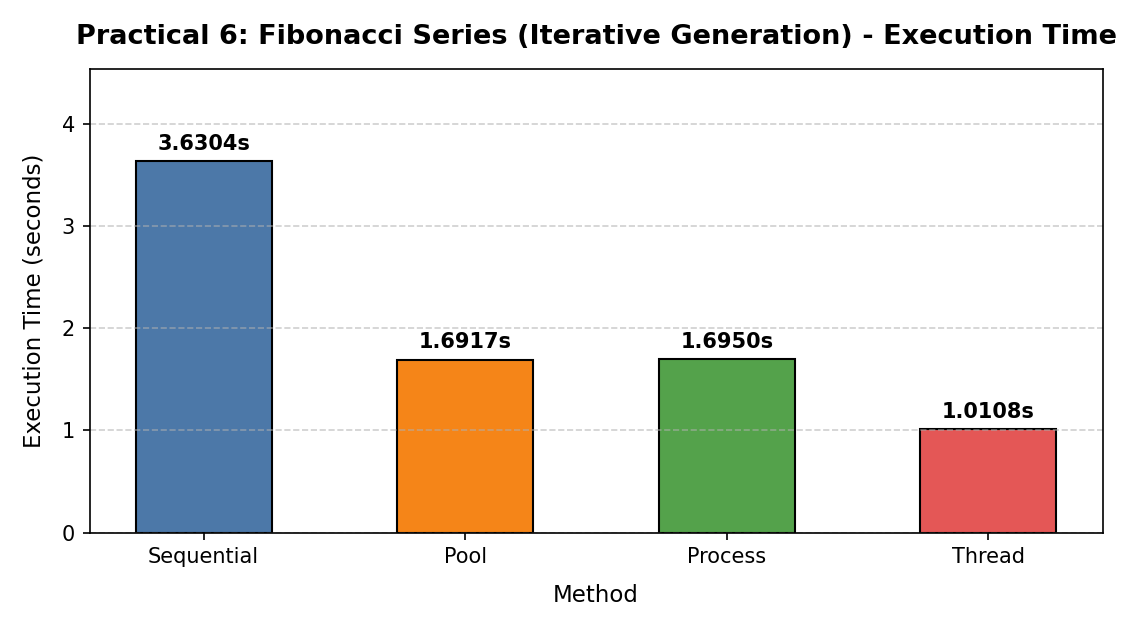

In [2]:
from IPython.display import Image, display
display(Image(filename='06_fibonacci_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


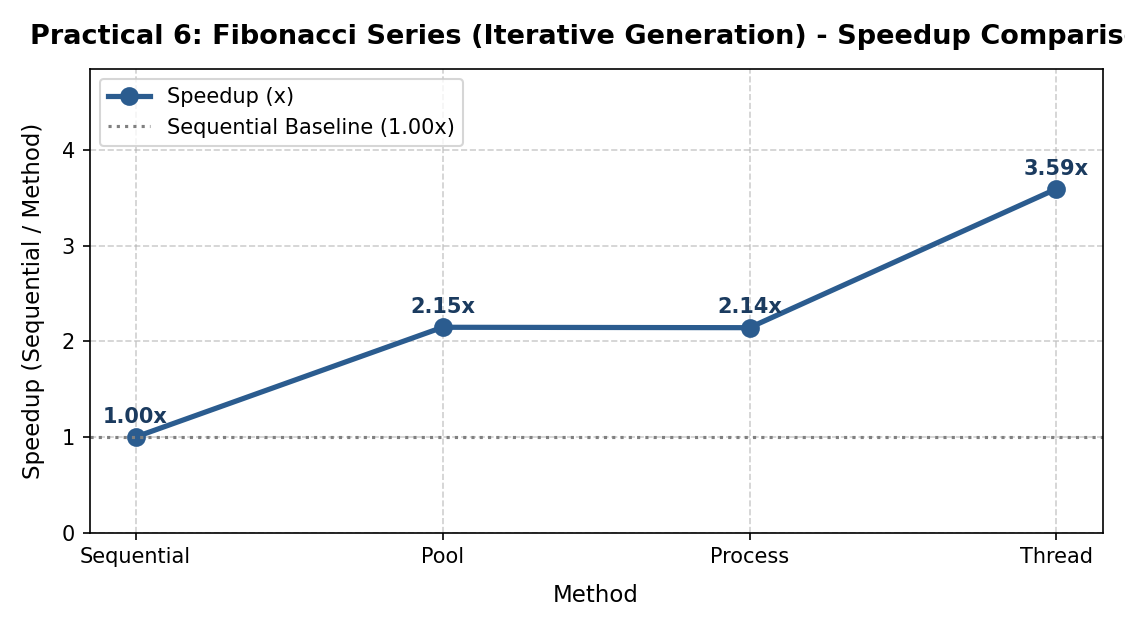

In [3]:
from IPython.display import Image, display
display(Image(filename='06_fibonacci_speedup.png'))
